# FOSSIL scanning strategy

This notebook shows how the FOSSIL pointing is built: one Cooler cycle of
3 Rings × 23 Scans, followed by the Recycling window. See `CONTEXT.md` for the
vocabulary and `configs/baseline.toml` for the parameters and their sources.

In [1]:
from pathlib import Path

import healpy as hp
import matplotlib.pyplot as plt
import numpy as np

from fossil_sim.config import load_config
from fossil_sim.operations import MODES, cycle_timeline, operation_flags
from fossil_sim.orbit import L2Orbit
from fossil_sim.scanning import cycle_pointing
from fossil_sim.simulation import run_simulation

config = load_config(Path.cwd().parent / "configs" / "baseline.toml")
tl = config.timeline
print(
    f"Scan {tl.scan_duration_s:.0f} s, Ring {tl.scans_per_ring * tl.scan_duration_s / 3600:.1f} h, "
    f"Cooler cycle {tl.cycle_duration_s / 3600:.1f} h"
)

Scan 1440 s, Ring 9.2 h, Cooler cycle 34.8 h


## Orbit and the anti-Sun direction

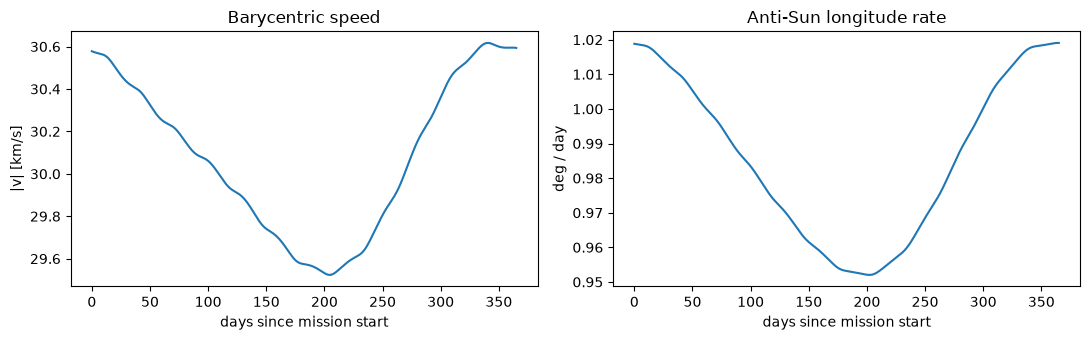

In [2]:
orbit = L2Orbit(config.orbit, config.simulation.mission_start_time, 365.25 * 86400)
days = np.linspace(0, 365, 2000)
pos_km, vel_km_s = orbit.position_velocity(days * 86400)
speed_km_s = np.linalg.norm(vel_km_s, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(days, speed_km_s)
axes[0].set(
    xlabel="days since mission start", ylabel="|v| [km/s]", title="Barycentric speed"
)
lon_rate_deg_day = np.rad2deg(
    np.gradient(orbit.anti_sun_longitude_rad(days * 86400), days)
)
axes[1].plot(days, lon_rate_deg_day)
axes[1].set(
    xlabel="days since mission start",
    ylabel="deg / day",
    title="Anti-Sun longitude rate",
)
fig.tight_layout()

## One Cooler cycle

Spin phase 0 (start of each Scan) is the point of the circle closest to the
north ecliptic pole. The 23 Scans of a Ring retrace the same circle; Rings are
stepped by one third of the solar motion over the cycle.

Ring steps [deg]: [0.49241124 0.49241124]
Max SAA in this cycle: 0.351 deg


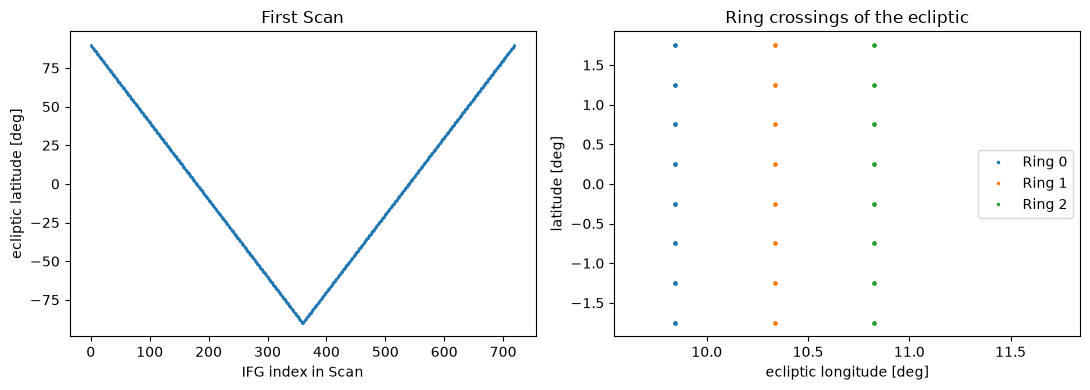

In [3]:
timeline = cycle_timeline(config, 0)
pointing = cycle_pointing(config, orbit, timeline)
mode, flags = operation_flags(config, timeline)
theta_rad, phi_rad = hp.vec2ang(pointing.boresight)
lat_deg, lon_deg = 90 - np.rad2deg(theta_rad), np.rad2deg(phi_rad)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
first_scan = timeline.scan_id == 0
axes[0].plot(timeline.ifg_in_scan[first_scan], lat_deg[first_scan], ".", ms=2)
axes[0].set(
    xlabel="IFG index in Scan", ylabel="ecliptic latitude [deg]", title="First Scan"
)
equator = np.abs(lat_deg) < 2
for ring in range(tl.rings_per_cycle):
    sel = equator & (timeline.ring_in_cycle == ring) & ~timeline.in_recycling
    axes[1].plot(lon_deg[sel], lat_deg[sel], ".", ms=3, label=f"Ring {ring}")
axes[1].set(
    xlabel="ecliptic longitude [deg]",
    ylabel="latitude [deg]",
    title="Ring crossings of the ecliptic",
    xlim=(lon_deg[equator].min() - 0.3, lon_deg[equator].min() + 2),
)
axes[1].legend()
fig.tight_layout()
print(
    "Ring steps [deg]:",
    np.rad2deg(
        np.arccos(np.sum(pointing.spin_axis[1:] * pointing.spin_axis[:-1], axis=1))
    ),
)
print(f"Max SAA in this cycle: {np.rad2deg(pointing.saa_rad.max()):.3f} deg")

## Modes and flags along the cycle

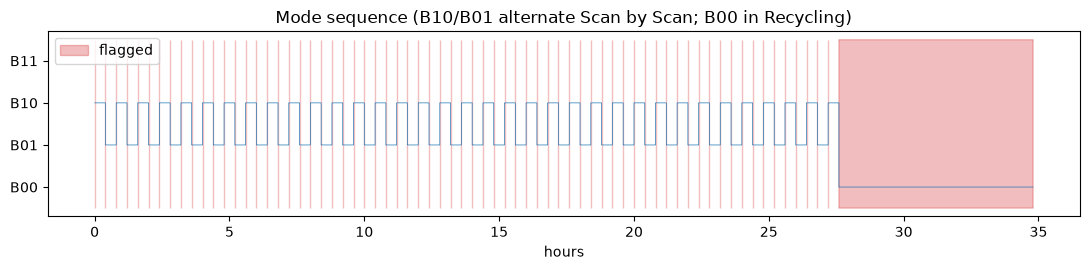

In [4]:
hours = timeline.time_mid_s / 3600
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.plot(hours, mode, drawstyle="steps-post", lw=0.5)
ax.set_yticks(range(len(MODES)), MODES)
ax.fill_between(
    hours,
    -0.5,
    3.5,
    where=flags > 0,
    color="C3",
    alpha=0.3,
    step="post",
    label="flagged",
)
ax.set(
    xlabel="hours",
    title="Mode sequence (B10/B01 alternate Scan by Scan; B00 in Recycling)",
)
ax.legend(loc="upper left")
fig.tight_layout()

## Hit map after 30 days

{'recycling': '20.69%', 'mode_switch': '0.11%', 'saa_exceeded': '0.00%', 'slew': '0.00%', 'any': '20.80%'}


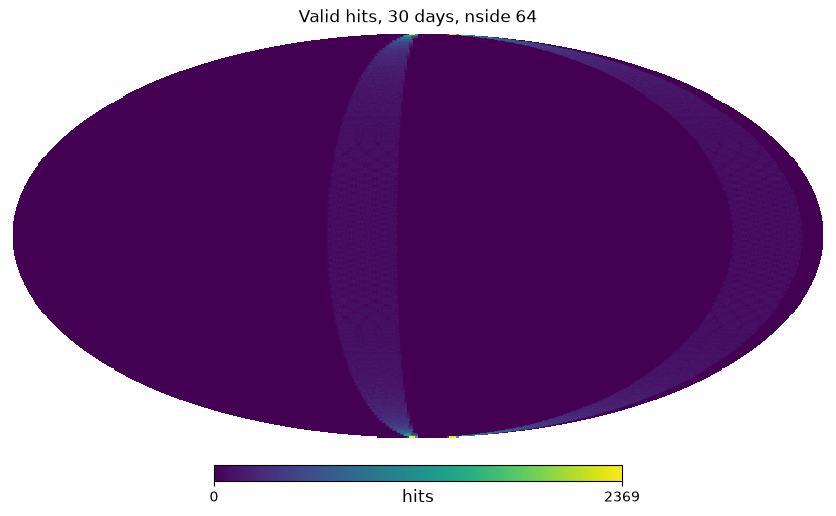

In [5]:
result = run_simulation(config, num_of_cycles=21, spectral=False)
hp.mollview(
    result.hit_maps.total(64), title="Valid hits, 30 days, nside 64", unit="hits"
)
print({name: f"{100 * frac:.2f}%" for name, frac in result.lost_fraction().items()})